# 10-存储器与文件系统

> 从“按地址读写”到“按文件组织”：先理解存储器的物理边界，再把 Flash、SD 卡接到 FatFS，最后设计可恢复的数据记录。

这是「嵌入式单片机一套通关」十二篇笔记的第 10 篇，承接第 08 篇 SPI 与第 09 篇 ADC，主题是 **SPI NOR Flash、SD 卡、FatFS、掉电保护和日志记录**。课程资料给出了 W25Q64/GD25Q32、SPI Flash+FatFS、SD 卡+FatFS 的移植思路；本篇补齐器件边界、接口契约和异常处理。

本篇示例以 GD32F407VET6、匹配 GD32F4xx SPL/CMSIS 和 FatFs R0.16 风格接口为背景。`app_*`、`board_*` 是应用层约定，不是厂商库现成 API。**没有进行 SDK 编译、烧录、上板运行或电气测量**；示例代码需要按实物原理图、芯片手册和 FatFs 版本适配。


## 1. 本篇资料、目标与阅读顺序

| 课程资料 | 本篇吸收的重点 |
|---|---|
| 存储器介绍 | RAM/ROM/EEPROM/NOR/NAND 的层次与边界 |
| SPI Flash🌟 | W25Q64、GD25Q32、PA4～PA7 接线、扇区/块/页 |
| SPI Flash+FatFS | FatFS 源码分组、`diskio.c` 胶水层和 Flash 选择 |
| SD卡+FatFS | GD32 SDIO 驱动、卡信息、底层 disk I/O |
| lvgl fatfs | 文件系统作为显示资源的后续接口（本篇只做衔接） |

官方 FatFs 资料明确区分应用接口和媒体访问接口：应用使用 `f_open`、`f_read`、`f_write`、`f_sync`，移植者提供 `disk_status`、`disk_initialize`、`disk_read`、`disk_write`、`disk_ioctl`。因此本篇先讲物理存储，再讲块设备，最后讲文件。

学习路线：第 2～7 节建立介质和接线概念，第 8～11 节掌握 NOR 驱动，第 12～14 节设计参数恢复，第 15～22 节完成 SD 卡与 FatFS 分层，第 23～29 节实现文件和日志，最后排错、自测和验收。

**三个验收结果**：裸驱动按范围读写并保留邻居；块层正确报告容量、状态和同步；文件层重新上电后能读回完整记录并识别错误尾部。能打印“写成功”只说明走过某条分支。

FatFs 是模块名称，FAT 是磁盘文件系统格式。课程说“方便在 FAT12/16/32 之间转换”，应理解为支持多种卷格式；切换格式通常涉及重新格式化和数据迁移，不是修改一个宏就无损转换。


## 2. 存储器的三个视角：易失性、粒度和接口

**易失性**回答“断电后还在不在”：SRAM、DRAM 断电丢失；EEPROM、Flash 属于非易失存储器。**粒度**回答“最小能怎样操作”：CPU 常按字节读写，Flash 常按页编程、按扇区/块擦除。**接口**回答“主控怎么到达它”：并行总线、SPI、I²C、SDIO 等。

| 介质 | 断电 | 典型访问粒度 | 适合放什么 |
|---|---|---|---|
| SRAM | 丢失 | 字节/字 | 栈、队列、DMA 缓冲 |
| MCU 内部 Flash | 保留 | 取指/编程页或行、擦除扇区 | 程序、少量参数 |
| SPI NOR Flash | 保留 | 读可细，页编程，扇区擦除 | 字库、图片、参数、日志 |
| EEPROM | 保留 | 字节或页写（看型号） | 小量配置、校准值 |
| SD 卡 | 保留 | 逻辑块，通常 512 字节 | 大文件、可拔出的数据 |

“ROM”是历史上的只读分类，不等于现在所有 ROM 器件都不可写；可电擦写的 EEPROM/Flash 仍然要遵守各自写入和擦除限制。寿命、保持时间、电压和温度必须看具体型号，不能把某个器件的“100 万次、100 年”当成通用保证。

运行状态放 RAM，跨重启状态放非易失存储。例如温度样本先在 RAM 缓冲再批量写 SD，校准系数启动时从 Flash 校验后读入 RAM，采样时直接使用 RAM 副本，降低延迟与磨损。

EEPROM 的字节写也有内部写周期；I²C EEPROM 常有页大小、页内回卷和 ACK polling。DRAM 需要刷新，SRAM 通常不需要；“断电是否丢失”和“运行时是否刷新”是两个问题。


## 3. 容量单位与地址范围

芯片名称常用 bit 容量，软件地址使用 byte。课程中的 W25Q64 是 `64 Mbit = 8 MiB`，GD25Q32 是 `32 Mbit = 4 MiB`。若按 `1 MiB = 1024×1024 byte` 计算，合法字节地址分别为：

| 器件 | 容量（字节） | 最后地址 |
|---|---:|---:|
| W25Q64 | 8×1024² = 8,388,608 | `0x7FFFFF` |
| GD25Q32 | 4×1024² = 4,194,304 | `0x3FFFFF` |

地址检查应先防止加法溢出：

```c
bool range_ok(uint32_t address, uint32_t length, uint32_t capacity)
{
    return address <= capacity && length <= capacity - address;
}
```

`address + length <= capacity` 在无符号整数溢出时可能错误；先做减法更安全。容量常量不能凭外壳丝印猜测，启动时可读 JEDEC ID 或 SFDP，再把容量交给分区和驱动。

W25Q64 的 8 MiB 对应 **2048 个 4 KiB sector、32768 个 256 B page、16384 个 512 B 逻辑 sector**；GD25Q32 对应 1024、16384、8192。提供给文件系统时还要扣除保留区。

课程容量图标为 W25Q128JV，不能把其最大地址 `0xFFFFFF` 用于 W25Q64。图可用来理解结构，地址须按实际容量重新计算。

`range_ok` 把零长度看作空操作，因此 address==capacity、length==0 合法；非零访问首字节必须小于 capacity。若不允许空操作，在所有接口中统一拒绝。C 片段类型来自 `<stdint.h>`、`<stdbool.h>`、`<stddef.h>`，内存操作来自 `<string.h>`。


## 4. 从程序、参数到日志：先做分区表

同一片 Flash 同时放程序、参数和日志时，必须先定义所有权。一个学习用布局如下，实际地址应按芯片容量和升级方案重新计算：

| 区域 | 例子 | 规则 |
|---|---|---|
| 引导/程序 | MCU 内部 Flash | 由启动和升级流程管理 |
| 资源区 | SPI NOR 前若干块 | 只读或版本化更新 |
| 参数区 | 两个 4 KiB sector | 双槽提交，保留旧副本 |
| 日志区 | 后续连续块或 FatFS 卷 | 批量写，定义满盘策略 |

分区起始地址应对齐物理擦除块；参数更新不能和图片写入共享同一擦除扇区而互相覆盖。把“地址常量散落在代码里”改成表格或结构体，启动时检查不重叠、不越界。

一个 **8 MiB SPI NOR** 教学布局采用半开区间 `[start,end)`：

| 用途 | 起始 | 结束（不含） | 大小 |
|---|---:|---:|---:|
| 资源 | `0x000000` | `0x200000` | 2 MiB |
| 参数槽 A | `0x200000` | `0x201000` | 4 KiB |
| 参数槽 B | `0x201000` | `0x202000` | 4 KiB |
| 示例文件卷 | `0x202000` | `0x800000` | 6,283,264 B |

文件卷有 12,272 个 512 B 逻辑 sector，LBA 0 映射到物理 `0x202000`。FatFS 看不到前面的资源和参数，格式化仅影响映射出的卷。布局是学习补充；换成 4 MiB 芯片必须重算。

内部 Flash 参数更新还涉及链接脚本、取指、擦除期间中断及程序区域保护。本篇不把内部 FMC 的操作函数混进 SPI NOR 驱动。


## 5. SPI NOR 的连接：信号方向要按主从关系判断

课程原理图中的 Flash 连接到 PA4～PA7：PA4 为 `SPI_CS`，PA5 为 `SPI_CLK`，PA6 为 `SPI_MISO`，PA7 为 `SPI_MOSI`，并有 3.3 V、100 nF 去耦、CS 上拉、WP/HOLD 的默认电平。CS 低有效；CS 高时器件释放总线。

器件命名容易看反：Flash 的 **DI 是器件输入，接主机 MOSI**；Flash 的 **DO 是器件输出，接主机 MISO**。课程文字把 DI/DO 与 MOSI/MISO 的括号写反，接线时应以原理图和芯片数据手册的引脚方向为准。WP、HOLD 未使用时也要保持在数据手册要求的有效/无效电平。

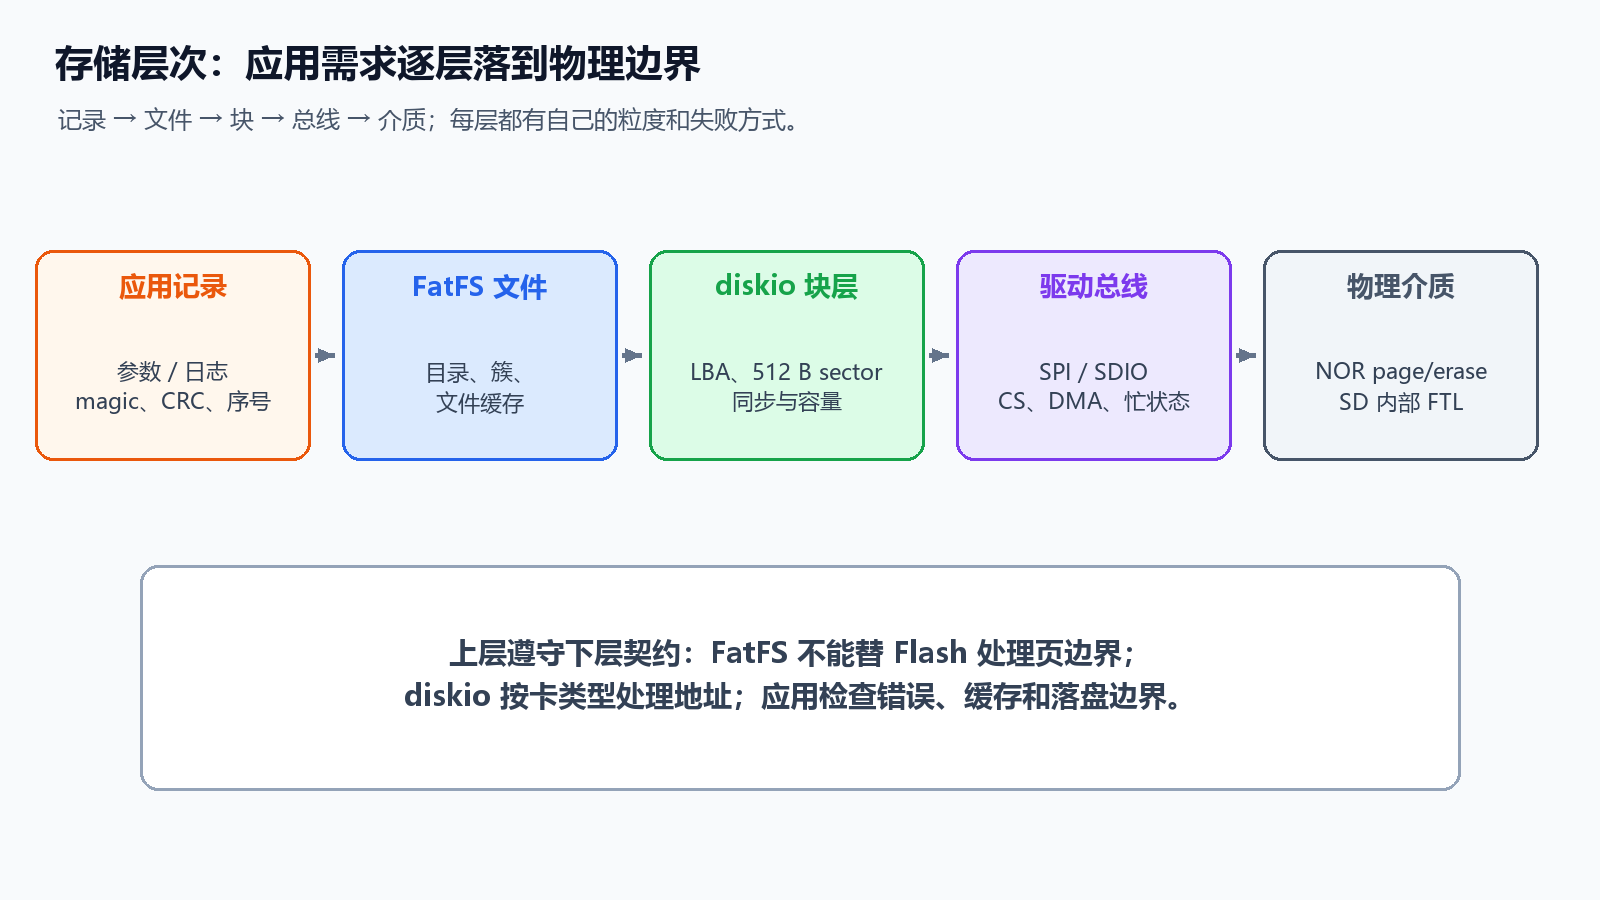

| MCU（课程图） | Flash | 方向 |
|---|---|---|
| PA4 / GPIO CS | /CS | MCU → Flash |
| PA5 / SPI CLK | CLK | MCU → Flash |
| PA6 / MISO | SO/DO | Flash → MCU |
| PA7 / MOSI | SI/DI | MCU → Flash |

复用功能、SPI 实例和时钟按 GD32 芯片/SPL 核对，不能机械复制 STM32 实例名。CS 初始化先为高，共享总线时为每个器件重新选择 mode/速率并独立片选。

图中 CS 10 kΩ 上拉、CLK 22 Ω 串阻、100 nF 去耦是板例；具体阻值按设计确定。普通 3.3 V Flash 与低压后缀器件可能有不同电压要求。

NOR 执行代码还需要 MCU 支持存储映射/XIP 和相关读协议。普通 `nor_read()` 只把数据搬到 RAM，不意味着 CPU 可直接在 SPI 地址取指。


## 6. JEDEC ID、状态寄存器和兼容性

典型 SPI NOR 启动流程是：复位或上电等待 → 读取 JEDEC ID → 根据型号选择容量、页大小、擦除命令和保护策略 → 读状态寄存器确认 BUSY/WEL → 执行测试读写。常见基本命令可以相似，但 W25Q64 与 GD25Q32 **不能仅凭名字声称完全兼容**；电压、地址宽度、状态位、深度掉电、SFDP 和时序仍要核对型号手册。

驱动接口可设计为：

```c
typedef struct {
    uint32_t capacity;
    uint32_t page_size;
    uint32_t erase_size;
    uint32_t jedec_id;
} nor_info_t;

bool nor_probe(nor_info_t *info);
bool nor_read(uint32_t address, void *buf, size_t length);
bool nor_program(uint32_t address, const void *buf, size_t length);
bool nor_erase_sector(uint32_t address);
```

`nor_probe` 失败时不能继续格式化或写入未知地址；把未知介质当成空白介质会造成不可逆破坏。

常见三字节地址 SPI NOR 的**教学命令集合**如下。完整 W25Q64/GD25Q32 后缀手册本篇未逐项核对，实际 opcode/状态位/时序按型号落实。

| 操作 | 常见 opcode | 要点 |
|---|---:|---|
| JEDEC ID | `0x9F` | 制造商、类型、容量识别 |
| Status 1 | `0x05` | 常见 BUSY 位0、WEL 位1 |
| Write Enable | `0x06` | 编程/擦除前的独立事务 |
| 普通读 | `0x03` | 命令、地址、数据 |
| Page Program | `0x02` | 不跨页 |
| 4 KiB erase | `0x20` | 对整个物理扇区 |
| 64 KiB erase | `0xD8` | 大范围擦除 |

`nor_program` 合同应明确“只写已擦除区域”，自动读改写另设接口；失败前可能有部分页已完成。写状态寄存器、Quad、深度掉电等功能不要在未识别器件时试探启用。


## 7. 0→1 需要擦除：为什么“写入”不是覆盖

NOR Flash 的编程通常只能把位从 1 变成 0；想把 0 变回 1，要先擦除包含它的 sector 或 block。擦除结果一般是全 `0xFF`，但擦除/编程的具体时间和寿命由型号保证。

| 操作 | 典型粒度 | 典型动作 |
|---|---|---|
| 读 | 任意连续字节 | 发送读命令、地址、时钟数据 |
| 页编程 | 不能超过一页 | 写使能→命令→地址→数据→等待 BUSY 清零 |
| 扇区擦除 | 常见 4 KiB | 写使能→擦除命令→地址→等待 |
| 块擦除 | 常见 64 KiB | 更大范围，时间和损耗也更大 |

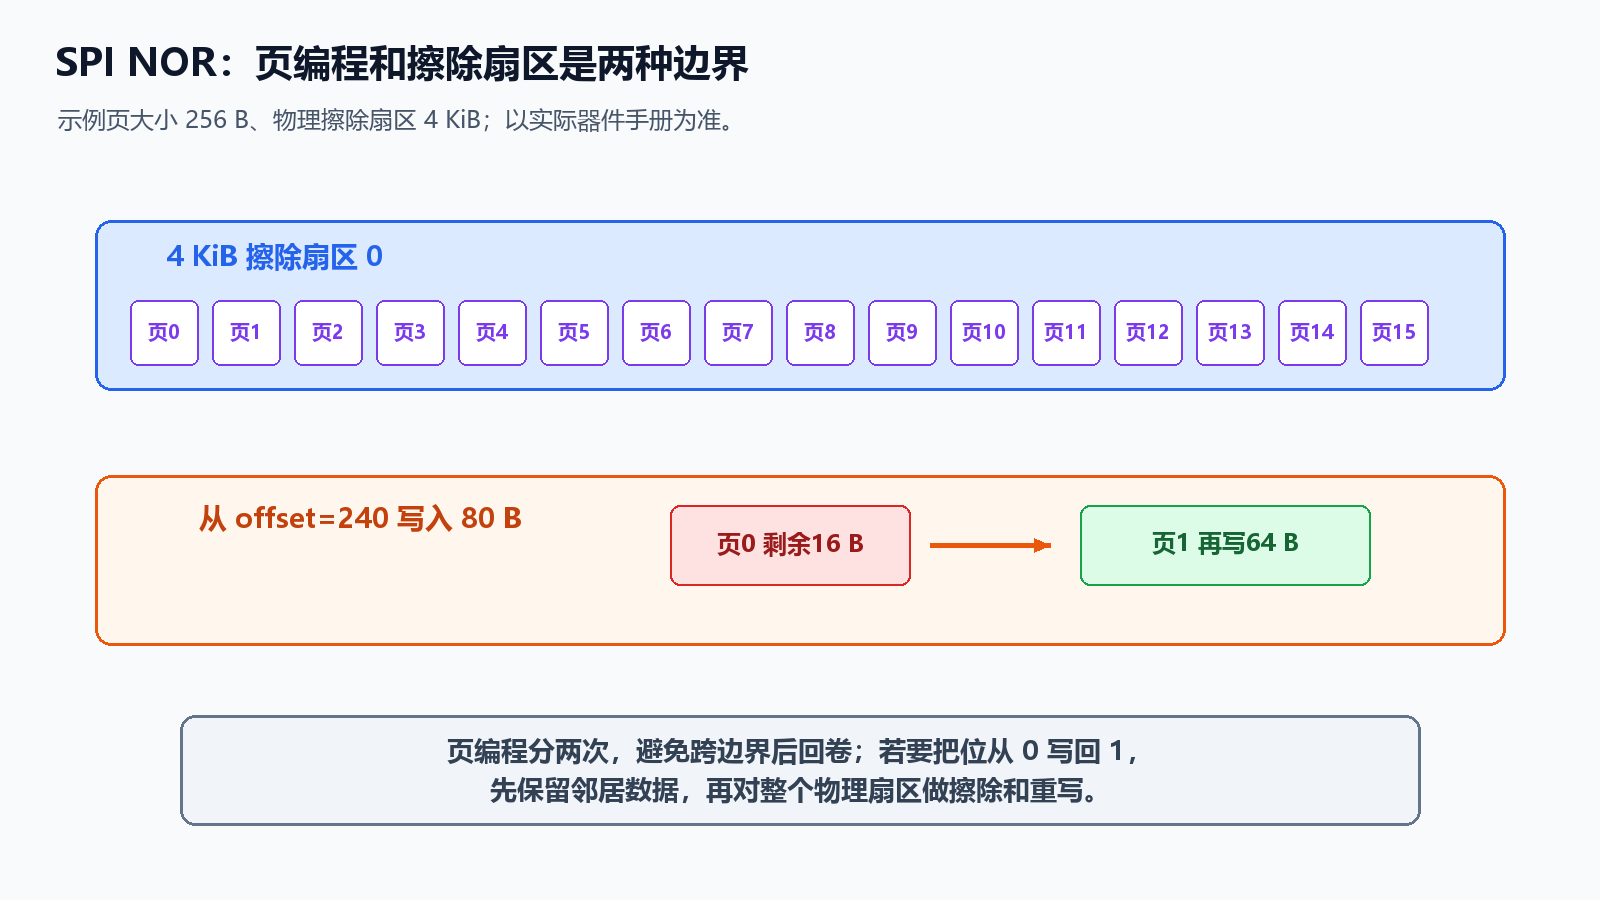

擦除前应确认该扇区内的所有数据是否都可丢弃；参数和日志若共享一个 sector，就必须读出保留数据、擦除、修改后整体写回。

旧字节 `0xA5` 写成 `0x81` 只需 1→0；写成 `0xE5` 需要 0→1。判定是否需要擦除的位条件：

```c
bool needs_erase(uint8_t old_value, uint8_t new_value)
{
    return (old_value & new_value) != new_value;
}
```

条件只判位变化；同页重复编程次数等限制仍由器件决定，不能由它推断可以无限原地重写。4 KiB NOR sector、512 B FatFS sector 和 SD 内部 erase block 虽然都叫扇区/块，但不是同一对象，表达时带单位。


## 8. 状态机：WEL、BUSY 与 CS 时序

写使能锁存位 WEL 通常在 `Write Enable` 后置 1，在编程/擦除结束或复位后清零。BUSY 置 1 表示内部高压操作进行中，期间不能把下一条普通命令当作已完成。

```text
CS↑ → 等待空闲 → CS↓ Write Enable → CS↑
CS↓ Program/Erase + address + data → CS↑
轮询 Status：BUSY=1 时等待；BUSY=0 后读回验证
```

等待函数必须有超时，不要无限轮询：

```c
bool wait_ready(uint32_t timeout_ms)
{
    uint32_t start = board_millis();
    while (nor_read_status() & NOR_BUSY) {
        if ((uint32_t)(board_millis() - start) >= timeout_ms) return false;
    }
    return true;
}
```

“SPI 发送完成”只说明最后一个时钟结束，不等于 Flash 内部编程完成；必须再等待 BUSY 清零。

状态读取也可能失败，应返回“错误码+输出状态”，不能用 0x00 同时表示就绪和总线错误。推荐：wait ready → Write Enable → 检查 WEL → 发编程/擦除 → 等 SPI 真正结束 → CS↑ → 等 BUSY 清零 → 校验。Write Enable 与 Program 使用两个独立 CS 事务。

时基在等待中必须继续运行。若 millis 由 ISR 更新，在禁中断区域等待会失去超时能力；超时还应小于计数周期且按器件最大操作时间设置。发送结束和内部操作结束分别验证。

共享总线用总线锁保护事务；整条参数/扇区更新还要用介质锁保护，避免两个任务在擦写间隙互相修改同一 sector。


## 9. 跨页写入：一次请求拆成多个 page program

课程器件常见页大小为 256 字节。很多 NOR 的页编程在页尾回卷，若直接从 `0x00F0` 写 32 字节，后 16 字节可能覆盖页头。因此驱动必须按页边界拆分：

```c
bool nor_program(uint32_t address, const uint8_t *src, size_t length)
{
    while (length) {
        size_t in_page = address % NOR_PAGE_SIZE;
        size_t chunk = NOR_PAGE_SIZE - in_page;
        if (chunk > length) chunk = length;
        if (!nor_page_program(address, src, chunk)) return false;
        address += (uint32_t)chunk;
        src += chunk;
        length -= chunk;
    }
    return true;
}
```

真实工程还应在入口检查地址范围、空指针、`length` 的类型转换和每个子操作的超时。跨页拆分只解决页边界，不能绕过“0→1 必须擦除”。

| 起始页内偏移 | 总长度 | 拆分结果（B） |
|---:|---:|---|
| 0 | 256 | 256 |
| 240 | 80 | 16、64 |
| 255 | 258 | 1、256、1 |
| 256 | 512 | 256、256 |

入口检查整个范围、length 的转换、非空指针。单页函数检查 chunk>0、不超过 page_size、首末地址在同一页，并管理 WEL、BUSY 和超时。失败返回 false 时，之前的页可能已写入，上层不能理解为“整个请求没有发生”。

页大小来自 probe 结果，不要让“256”散落在多个函数中；本篇表格采用常见 256 B 页教学模型。


## 10. 擦除前读改写：保留同一扇区的邻居数据

若只想改 sector 中的几个字节，而其余字节必须保留，可按以下步骤操作：

1. 把整个 4 KiB sector 读入 RAM 缓冲。
2. 在缓冲中修改目标范围，并检查新值是否越界。
3. 写使能、擦除 sector，等待 BUSY 清零。
4. 将缓冲按页编程回去。
5. 读回整个范围或关键记录，校验 CRC/内容。

```c
bool sector_update(uint32_t base, uint32_t offset,
                   const void *data, size_t length)
{
    uint8_t cache[4096];
    if (offset > sizeof cache || length > sizeof cache - offset) return false;
    if (!nor_read(base, cache, sizeof cache)) return false;
    memcpy(cache + offset, data, length);
    if (!nor_erase_sector(base)) return false;
    if (!nor_program(base, cache, sizeof cache)) return false;
    return verify_bytes(base + offset, data, length);
}
```

这段代码需要 4 KiB RAM；若 RAM 紧张，可采用更小的专用分区、外部缓冲或日志追加，不能把“只写几个字节”误认为 Flash 支持字节覆盖。

上面的 `sector_update` 是单扇区流程示意：前提是 base 对齐 4096、整个扇区在所属分区内、data 有效且调用持锁。4 KiB cache 可放专用静态区并串行使用，任务栈要经过预算。跨物理扇区请求按剩余 sector 空间分别处理。

只验证目标修改范围不够；验收应把整个读回 sector 与合并后的 cache 比较，确认邻居也保存。**读改写保留邻居，但不保证掉电保留邻居**：擦除后、重写前断电，RAM 也丢失。参数使用双槽；一般块层需要持久日志/映射或备用 sector 提交。

追加到已擦好的区域可以直接页编程，但要明确已擦范围、写指针和恢复规则，不能让它越过资源/参数区。


## 11. 保护、失败和有限重试

写保护脚、状态寄存器保护位、深度掉电和电源跌落都可能使写入失败。驱动应分别报告：参数错误、未识别器件、超时、写保护、读回不一致，而不是统一返回“成功”。

重试只适合短暂总线错误，建议次数很小并记录原因；擦除超时后不要立即重复擦同一扇区。发生读回不一致时，应把介质标为不可信，避免应用继续追加数据造成更大损坏。

| 底层状态 | diskio 映射 | 处理 |
|---|---|---|
| 未初始化/移除 | RES_NOTRDY | 停止写入，检测状态 |
| 写保护 | RES_WRPRT | 报告只读 |
| 参数/范围错 | RES_PARERR | 修正映射或调用 |
| 超时/通信/验证失败 | RES_ERROR | 保存诊断，恢复介质 |
| 完成 | RES_OK | 上层检查文件结果 |

超时意味着本次操作结果未知，不等于“还没写”。不要盲目再次擦除；先确认 ready、读取状态和内容。已挂载且有文件打开时，不得擅自全盘擦除、换卡或重置后继续使用旧文件对象。


## 12. 记录结构：让一串字节变成可检查的数据

参数、校准值和日志都应带元数据。一个固定记录可以包含：

| 字段 | 作用 |
|---|---|
| magic | 判断是不是本格式 |
| version | 结构版本，升级时区分布局 |
| length | 有效负载长度，防止越界解析 |
| sequence | 新旧记录比较 |
| payload | 实际参数或采样值 |
| crc32 | 检查记录内容是否被破坏 |
| commit | 最后写入的提交标记 |

CRC 能发现很多随机错误，但不能证明写入具有原子性；掉电可能发生在 CRC、payload 或提交标记的任意一步。提交标记必须最后写，并且恢复程序只接受 magic、长度、CRC、commit 都正确的记录。

用固定字节流序列化，明确端序与覆盖范围。本篇 CRC-32/ISO-HDLC：正常多项式 0x04C11DB7，反射常数 0xEDB88320，初值/末尾 xor 均为 0xFFFFFFFF；标准向量 `"123456789"` → `0xCBF43926`。

```c
uint32_t app_crc32(const uint8_t *data, size_t length)
{
    uint32_t crc = 0xFFFFFFFFu;
    while (length-- != 0u) {
        crc ^= *data++;
        for (unsigned bit = 0; bit < 8; ++bit)
            crc = (crc >> 1) ^ ((crc & 1u) ? 0xEDB88320u : 0u);
    }
    return crc ^ 0xFFFFFFFFu;
}
```

CRC 覆盖 magic/version/length/sequence/payload，不包括 CRC 自身与 commit。空数据结果为0，非空时指针必须有效。读取时先限制 length/version 和业务范围，再算 CRC，不能先信任介质中的长度并越界读取。CRC 能检错但不修复错误，也不是认证机制。


## 13. 双槽参数与掉电恢复

把同一份参数放到 A/B 两个扇区：写新槽、校验读回、最后提交；启动时扫描两个槽，选择 CRC 正确且 sequence 更新的那一个。旧槽不要先擦掉，这样写新槽中途断电仍有旧值可用。

```text
读取 A、B → 过滤 magic/length/CRC/commit
        → 没有有效槽：使用安全默认值并报警
        → 一个有效槽：使用它
        → 两个有效槽：按序列号选择更新者
```

序列号回卷比较只能在“两个候选的距离小于序列空间的一半”这一约束下成立，例如无符号 32 位序列采用 `delta = a - b; delta != 0 && delta < 0x80000000u`，但不能让设备离线积累超过半个空间后再盲目比较。提交字节也必须确认器件可从擦除值写成目标值。

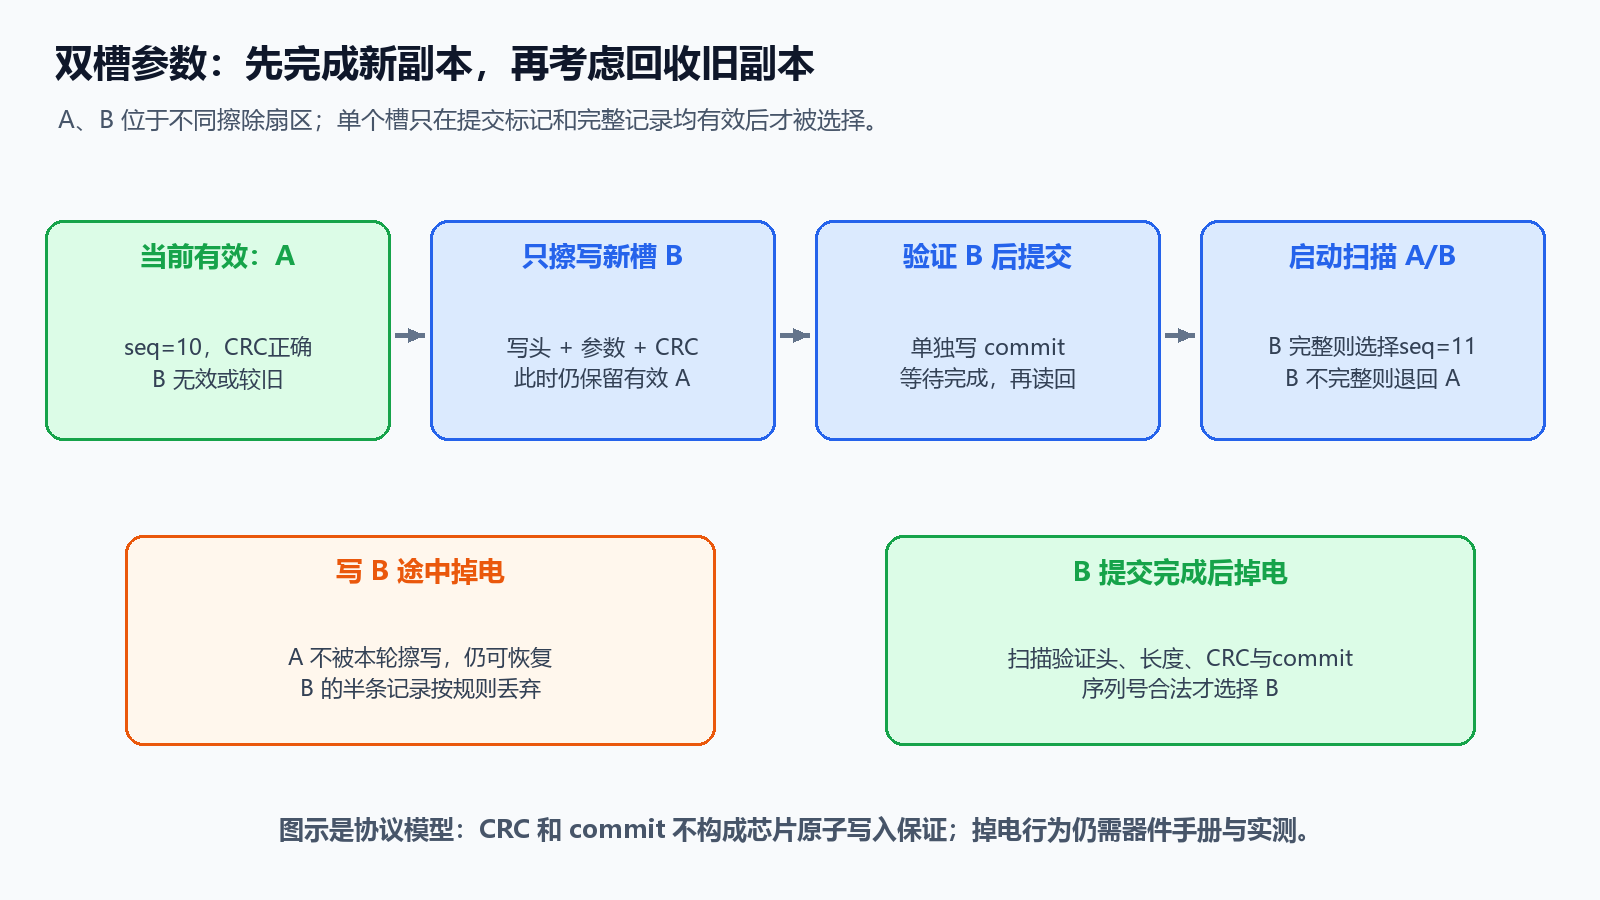

一槽一个 4 KiB sector，正文不超过 4092 B，最后四字节留给 commit。擦除为 FFFFFFFF，提交标记选固定非 FF 常量。正文全部完成并读回正确后再单独写 commit，等待并再次验证完整记录。

```text
A(seq10有效)保留 → 擦B → 写B正文/CRC → 校验B → 写commit
              → 等待B完成并验证 → 发布RAM中的新参数
下一次更新需要时才用A作为新槽；先擦A之前仍保留B。
```

| 断电时刻 | 恢复 |
|---|---|
| 擦B/写B正文期间 | 选择A |
| 正文完整、commit未写 | 选择A |
| commit部分写入 | 只有完整匹配且CRC通过才可接受B，否则A |
| B验证完成后 | 选择B的seq11 |

sequence 相等有固定选择规则并记录异常；差值为半范围无法判断。可用定义明确的无符号差值：

```c
bool app_seq_newer(uint32_t a, uint32_t b)
{
    uint32_t delta = a - b;
    return delta != 0u && delta < 0x80000000u;
}
```

模型假定擦写B不破坏A；欠压时芯片影响范围要看实物手册与故障注入。CRC 有误碰撞概率，commit 也不保证物理写入原子，重要参数应结合电源保持、冗余和器件明确保证。


## 14. 磨损、写放大与更新频率

若一个 4 KiB sector 每次参数更新都擦除一次，寿命主要由该 sector 的擦写次数决定。把计数器、状态和配置放在同一个热扇区会加剧磨损。常见策略是：追加日志、多个槽轮换、按变化才写、批量同步、把大文件交给带 FTL 的 SD 卡。

粗略估算写入寿命：若单个热扇区的假设预算为 E 次，每次擦写产生 B 字节有效数据，每天写到该处 D 字节，寿命天数约 E×B/D。这是估算模型，不是器件保证；实际还受温度、写放大、掉电和坏块影响。

假设一个 sector 预算 E=100000 次，每秒擦一次仅约1.16天消耗该预算；每小时一次约11.4年。**100000 是计算假设，不是本篇核实的型号寿命规格。**

若有均衡策略，理想天数可估为 `E×可用物理容量/(每日有效写入×写放大WA)`。例如4 MiB、每天1 MiB、E=100000、WA=10得到40000天数学上限；温度、保持、坏块和不均衡会限制实际产品。

双槽保留副本但不是全盘均衡；FAT/目录元数据仍可能反复擦同一物理 sector。不能用“日志换了文件名”证明磨损热点消失。


## 15. NOR、NAND 和 SD 卡不要混为一谈

NOR 通常适合随机读取、小容量代码/资源；NAND 密度更高，常按页读写、按块擦除，并需要坏块管理或 FTL。SD 卡内部已经包含控制器和 FTL，负责地址转换、磨损均衡和纠错；主控把它看成逻辑块设备。

这并不表示“所有 NAND 读都慢于所有 NOR”或“所有 SD 卡都一样快”。接口频率、卡型号、控制器、写入块大小和内部回收都会改变性能。工程上要用目标介质的数据手册和实测结果。

SPI NOR 串行发送地址，不能照搬“并行地址/数据线分开”的描述。NAND 有页数据区、备用区、ECC 和坏块需求，不能直接换芯片名复用 NOR 的 0x03 驱动。

SD 卡隐藏物理映射，但不是无限寿命，也不保证任意掉电下文件安全。选择具备保护能力的卡，应核对明确保证、温度和工作负载，而不是只看容量与品牌。


## 16. SD 卡的 SPI/SDIO 与逻辑块

课程采用 GD32 标准库 SDIO 示例，提取 `sdcard.c/.h` 后加入 Drivers 分组，再把卡驱动映射到 FatFS 的 `diskio.c`。SD 卡也可通过 SPI 连接；SPI 模式更通用，SDIO/SDMMC 通常能提供更高吞吐，具体取决于 MCU 和卡。

SD/MMC 上层以 512 字节数据块传输；SDHC/SDXC 使用块地址，高容量卡不能按旧 SDSC 的字节地址习惯直接计算。初始化需要确认版本、容量类型、工作电压和 ready 状态，卡忙时要等待。卡的写电流和插拔瞬态也要纳入电源设计。

课程路径为 `GD32F4xx_Firmware_Library\Examples\SDIO\Read_write`。仍须核对 sdcard.c 的引脚复用、时钟、总线宽度、DMA/IRQ、卡检测和标准库版本，本篇没有凭空给完整 SDIO 引脚表。

低速识别 → 确认卡类型/电压 → 初始化ready → 读容量 → 设总线/速率 → 单块/多块验证。读出一段 CID/CSD 不等于完整读写可用。

高容量卡的 LBA3 是块地址3，旧 SDSC 命令参数可能需要1536字节地址。应由底层按类型转换一次；若 sdcard.c 已做转换，diskio 不要再次乘512，必须阅读所用 API 的地址单位。


## 17. 块设备接口：FatFS 只看到 LBA

FatFS 通过 `pdrv`、LBA sector 和 count 访问介质。应用不应直接调用 `disk_read`/`disk_write` 去改 FAT 表；这些函数是文件系统与具体驱动之间的接口。

```c
DRESULT disk_read(BYTE pdrv, BYTE *buff, LBA_t sector, UINT count);
DRESULT disk_write(BYTE pdrv, const BYTE *buff, LBA_t sector, UINT count);
DSTATUS disk_initialize(BYTE pdrv);
DSTATUS disk_status(BYTE pdrv);
DRESULT disk_ioctl(BYTE pdrv, BYTE cmd, void *buff);
```

`disk_read`/`disk_write` 必须检查设备初始化状态、起始 sector、count 和缓冲区范围。多 sector 请求不要无意义地拆成单 sector 事务，否则吞吐下降，卡内部写放大也可能增加。

返回值类型不能混淆：`disk_status/initialize` 返回位标志 DSTATUS（如 STA_NOINIT、STA_NODISK、STA_PROTECT），`disk_read/write/ioctl` 返回 DRESULT，应用文件 API 返回 FRESULT。不要拿底层 bool 值直接当 FRESULT 返回，数值碰巧相同也不代表语义相同。

针对上面的 8 MiB 示例分区，安全映射可写成独立算法；仅适用于此教学几何，`disk_*` 需先检查 pdrv 和状态：

```c
#define APP_VOL_BASE    0x202000u
#define APP_VOL_BYTES   6283264u
#define APP_SECTOR_SIZE 512u
#define APP_SECTOR_N    (APP_VOL_BYTES / APP_SECTOR_SIZE)

bool app_map_lba(LBA_t sector, UINT count,
                 uint32_t *address, size_t *bytes)
{
    if (address == NULL || bytes == NULL || count == 0u) return false;
    if ((uint64_t)sector >= APP_SECTOR_N) return false;
    if ((uint64_t)count > APP_SECTOR_N - (uint64_t)sector) return false;
    /* 前面已限在小分区中，以下转换/乘法不会越过32位范围 */
    *address = APP_VOL_BASE + (uint32_t)sector * APP_SECTOR_SIZE;
    *bytes = (size_t)count * APP_SECTOR_SIZE;
    return true;
}
```

每次请求假定 buff 至少有 count×512 字节，这是 FatFS 与调用者的合同。SDIO DMA 未必支持任意 BYTE* 对齐或任何 RAM 区域；若需要 word 对齐/专用RAM，应使用受锁保护的对齐 bounce buffer，不要直接强转未对齐 BYTE* 为 uint32_t*。

读取多个 sector 成功时必须真的填满；底层短读不能包装成 RES_OK。多块 API 的 count、字节数和传输完成状态分别核对，尤其使用 DMA 时返回点必须与缓存所有权匹配。


## 18. FatFS 分层：应用、ff、diskio、总线

典型数据路径如下：

```text
app_logger.c / app_file.c
        ↓ f_open / f_write / f_sync
ff.c + ff.h（FAT/FAT32/exFAT 逻辑）
        ↓ disk_*
diskio.c（移植胶水）
        ↓
SPI NOR 驱动或 GD32 SDIO 驱动
        ↓
Flash/SD 卡硬件
```

课程中 `ff.c` 是核心，`diskio.c` 提供底层访问，`ffunicode.c` 支持长文件名相关编码，`ffsystem.c` 在需要操作系统同步/内存管理时使用。`integer.h` 和 `flash_choose.h` 是否需要，取决于所用 FatFS 版本与工程组织，不能机械复制旧教程。

`ff.c/ff.h/ffconf.h/diskio.h/ffunicode.c` 应来自同一版本。当前官方文档是 R0.16，本篇依此解释接口；课程具体压缩包版本未完全识别，不声称可以原样混用。较旧版本可能用 DWORD sector、不同 `f_mkfs` 原型和互斥函数名。

最小移植步骤：

1. 先把独立介质驱动读写验收完成。
2. 将整套 FatFs 核心和对应配置加入 Middleware。
3. 在 diskio 中固定物理设备号映射；实现状态、初始化、范围读写和同步。
4. 使用 ASCII 8.3 测试路径、固定扇区大小及单任务，先完成文件回读。
5. 再逐项开启多个卷、长文件名、RTOS、资源访问，并记录 RAM/Flash 占用。

`ffsystem.c` 是平台同步和动态内存钩子的参考，FatFs 本身不要求一定运行在桌面 OS。`ffunicode.c` 也不等于“加入它就自动支持所有UTF-8文件名”，还要配置 LFN、TCHAR 编码和路径调用约定。


## 19. 用 FatFS 管 SPI NOR：逻辑 sector 与物理 erase

FatFS 的逻辑 sector 常设为 512 字节，而 SPI NOR 的物理擦除 sector 可能是 4096 字节。于是一次 `disk_write` 可能需要读改写整个 4 KiB 物理 sector：

```text
逻辑 LBA 512 B → 定位物理 4 KiB → 读入缓存
                → 合并 512 B 修改
                → 擦除 4 KiB → 按页编程 → CTRL_SYNC
```

`GET_BLOCK_SIZE` 的单位是逻辑 sector：4 KiB / 512 B = 8，而不是直接返回 4096。缓存、并发和掉电策略由 disk I/O 层承担；FatFS 本身不会替你实现 Flash 的 FTL。

为理解逻辑 sector 覆盖，假设更新 LBA11：对应字节偏移5632，它位于第二个物理 sector（base4096）中，内部offset1536。必须保留该物理 sector 其它7个逻辑 sector。若 count=2，从 LBA7 开始写，请求跨物理边界：先处理第一个4 KiB末512 B，再处理下一个4 KiB首512 B。

一种教学适配器是“单个4 KiB cache + 固定映射 + 读改擦写”。它能展示块语义，但存在掉电损坏邻居和元数据热点，不适合作为已完成的可靠产品方案。更完整 FTL 需要备用块、持久映射、写后提交、恢复扫描与均衡；采用合适的 Flash 文件系统也可以重新评估，但不可把更换库当成不需要验证。

只用 NOR 的工程也可把逻辑 sector 配为4096，匹配物理擦除粒度；FatFs 允许512/1024/2048/4096。这样增加每卷/每文件缓存和小文件成本，而且**仍不解决掉电原子性与磨损**。若同一套 FatFs 同时管理SD(512)与NOR(4096)，配置可变sector并按设备报告，不能固定512还在某个驱动中偷偷用4096。


## 20. `disk_ioctl` 的五个关键命令

官方接口要求移植层正确处理：

| 命令 | 含义 |
|---|---|
| `CTRL_SYNC` | 等待延迟写入真正完成 |
| `GET_SECTOR_COUNT` | 返回可用逻辑 sector 数 |
| `GET_SECTOR_SIZE` | 返回 512/1024/2048/4096 等逻辑扇区大小 |
| `GET_BLOCK_SIZE` | 返回 Flash 擦除块对应的逻辑 sector 数 |
| `CTRL_TRIM` | 告知介质某段数据不再需要（可选） |

如果每次 `disk_write` 都已同步完成，`CTRL_SYNC` 可以是空操作；如果驱动有写回缓存，就必须真正刷到介质。`GET_SECTOR_COUNT` 错误会影响格式化和越界判断，不能填一个“看起来够大”的常量。

| ioctl | buff 指向类型（R0.16） | 此教学NOR卷返回 |
|---|---|---|
| GET_SECTOR_COUNT | LBA_t | 12272 |
| GET_SECTOR_SIZE | WORD | 512 |
| GET_BLOCK_SIZE | DWORD | 8 |
| CTRL_SYNC | 无参数，可为 NULL | 完成所有挂起操作后成功 |

先检查 pdrv、初始化状态和命令；需要输出的命令再检查 buff。不能为所有命令统一拒绝 NULL，否则合法的 CTRL_SYNC 会失败。固定 `FF_MIN_SS==FF_MAX_SS` 时 FatFs 通常不调用 GET_SECTOR_SIZE，但实现与声明仍应一致。

`disk_write` 允许延迟完成，但返回后调用者的 buff 就不再有效：延迟驱动必须复制数据到自己拥有的缓存或保证实际传输不再使用该缓冲；不能返回后让 DMA 继续读已被上层重用的数组。CTRL_SYNC 应刷 dirty cache 并等待Flash BUSY或SD驱动报告写过程完成；收到SPI/DMA结束中断还不够。

CTRL_TRIM 只表示“不再需要”，不等于安全删除或必须立即擦除。NOR 的请求若只涉及部分物理 sector，不能擦掉其中仍在用的其它逻辑数据；教学移植可先禁用TRIM。SD卡内部erase块大小不知道时按官方约定报告1，不凭卡容量猜固定值。


## 21. 挂载、格式化和卷状态

`f_mount` 是给逻辑卷注册 `FATFS` 工作区；`opt=0` 可能只注册而延迟检测，`opt=1` 才强制尝试挂载。挂载成功不等于介质永远在线，拔卡、复位或掉电后要重新初始化。

`f_mkfs` 会创建 FAT/exFAT 卷，可能覆盖整个目标区域。它不是“读不到文件就自动调用”的修复函数；`FR_DISK_ERR` 可能表示总线、电源、卡忙、地址或驱动问题。格式化只能在明确的测试区、用户确认或恢复策略中执行，不能在生产设备启动时无条件格式化。

注册的 `FATFS` 对象必须持续存在，不能在某个函数的局部栈上创建后挂载并返回。一个教学初始化片段是：

```c
static FATFS app_fs;      /* 生存期覆盖整个卷的使用过程 */
FRESULT app_mount(void)
{
    return f_mount(&app_fs, "0:", 1);
}
```

`FR_NO_FILESYSTEM` 也不等于“盘空了”：可能是格式不支持、LBA映射错误、扇区大小错误、卷损坏或确实没格式化。先确认裸读和几何正确，再决定是否在专用测试介质上建卷。`FR_NOT_READY` 优先处理初始化，`FR_DISK_ERR` 优先处理物理I/O，不能全部进格式化分支。

R0.16 的格式化原型为 `f_mkfs(path, const MKFS_PARM *opt, work, len)`，更旧示例常有不同参数。格式化工作缓冲至少 FF_MAX_SS，但不代表整个文件系统只用这么多RAM。格式化、重新mount和换卡都应在停止其它访问、关闭或终止文件后管理；重新mount会使该卷原有文件/目录对象无效。

格式化选择FAT/FAT32由卷大小和簇数共同决定。4/8 MiB小NOR不应强制“必须FAT32”；SDXC默认exFAT也不能在FF_FS_EXFAT=0时成功识别。


## 22. 配置 `ffconf.h`：功能换资源

常见配置项包括 `FF_FS_READONLY`、`FF_USE_MKFS`、`FF_USE_LFN`、`FF_MAX_LFN`、`FF_FS_TINY`、`FF_FS_REENTRANT`、`FF_FS_EXFAT` 和扇区大小范围。开启长文件名需要 `ffunicode.c`，静态工作缓冲在多任务下可能不安全；开启 RTOS 重入则需要实现 `ff_mutex_*`。

SD 卡容量、文件大小和协议版本决定 FAT32/exFAT 是否适用；不能只因为电脑能打开某张卡，就假设当前 FatFS 配置支持它。先固定 FatFS 版本和配置，再写 `diskio.c`，否则教程中的宏名和结构体可能与工程不一致。

先用简单配置验证：

| 配置 | 教学起点 | 开启后的责任 |
|---|---|---|
| FF_FS_READONLY | 0 | 实现写/同步/时间接口 |
| FF_MIN_SS / FF_MAX_SS | 都512（本例） | 若不同需GET_SECTOR_SIZE |
| FF_USE_LFN | 0，先8.3文件名 | LFN缓冲、Unicode转换和RAM |
| FF_FS_REENTRANT | 0，单日志任务 | 多任务用对应版本mutex钩子 |
| FF_USE_MKFS | 测试构建可为1 | 在明确测试介质建卷 |
| FF_USE_TRIM | 0 | 若启用核对擦除/释放语义 |

这是一组学习起点，并非完整 ffconf.h 文件。真实工程应从同版模板修改，保留必需版本标识，查看链接器统计。LFN=2 用栈，LFN=3 用堆并提供 `ff_memalloc/free`；LFN=1 静态缓冲限制重入。UTF-8 路径常配 `FF_LFN_UNICODE=2` 并启用LFN，但最终以当前版本配置为准。

`FF_FS_LOCK` 控制重复打开、删除和改名规则，`FF_FS_REENTRANT` 控制同卷访问互斥，它们解决不同问题；打开宏后仍要保护复合应用操作及底层共享总线。

时间戳可承接第07篇RTC：当 `FF_FS_NORTC=0`，提供 `get_fattime`，年份相对1980，月份/日期/时分秒按FAT位域编码，秒为2s粒度。无RTC可配置固定时间，但日志内时间戳应另外记录来源和有效状态，不能把固定文件日期当实际采样时间。


## 23. 文件 API 的正确检查顺序

写文件至少检查三件事：`FRESULT`、实际写入字节数 `bw`、必要时的同步结果。

```c
FRESULT fr;
UINT bw;
fr = f_write(&fil, buf, len, &bw);
if (fr != FR_OK || bw != len) {
    /* 记录错误；磁盘满和介质错误都不能当成功 */
}
fr = f_sync(&fil);       /* 长时间打开写入的日志周期同步 */
if (fr != FR_OK) { /* 进入只读/故障策略 */ }
```

`f_read` 中 `br < btr` 可能是正常 EOF，也可能伴随错误，要结合 `FRESULT` 判断。`f_close` 会刷新已改变的文件；如果关闭失败，不能把数据当成已落盘。

完整的“创建→写→关闭→重新读”示例在**已挂载测试卷**上运行；使用8.3路径 `0:/NOTE10.TXT`，文件已存在时 CREATE_NEW 返回 FR_EXIST，不覆盖旧文件。没有错误重试和格式化分支。

```c
/* 依赖同版ff.h，以及stdint.h、stdbool.h、string.h；
   app_report_* 是需要自行实现的诊断接口。 */
bool app_file_roundtrip(void)
{
    static const char text[] = "MCU storage note 10\r\n";
    FIL file;
    UINT actual = 0;
    FRESULT fr, close_fr;
    bool ok;

    fr = f_open(&file, "0:/NOTE10.TXT", FA_WRITE | FA_CREATE_NEW);
    if (fr != FR_OK) { app_report_fs(fr); return false; }

    fr = f_write(&file, text, (UINT)(sizeof text - 1u), &actual);
    ok = (fr == FR_OK && actual == sizeof text - 1u);
    if (!ok) app_report_write(fr, actual, sizeof text - 1u);

    close_fr = f_close(&file); /* 自带同步，检查而不掩盖写错误 */
    if (close_fr != FR_OK) {
        app_report_fs(close_fr);
        /* 对象无法确认已关闭：停止卷访问，按应用故障流程处理 */
        return false;
    }
    if (!ok) return false;

    fr = f_open(&file, "0:/NOTE10.TXT", FA_READ | FA_OPEN_EXISTING);
    if (fr != FR_OK) { app_report_fs(fr); return false; }
    char readback[sizeof text - 1u];
    fr = f_read(&file, readback, (UINT)sizeof readback, &actual);
    ok = (fr == FR_OK && actual == sizeof readback &&
          memcmp(readback, text, sizeof readback) == 0);
    close_fr = f_close(&file);
    return ok && close_fr == FR_OK;
}
```

readback没有C字符串终止符，故使用memcmp，不把它直接传给 `printf("%s")`。一般二进制文件也是“缓冲+有效字节数”，不能依靠strlen。大于UINT范围的文件传输必须拆分，避免把size_t直接转换导致截断。

日志长时间打开时周期f_sync，每次检查结果；最终关闭调用f_close即可，无需为了“保险”在其前无条件再重复sync。关闭失败时应保留错误、停止对此对象的常规操作并走有限恢复流程，不能继续向栈上已销毁的FIL写。


## 24. 打开标志、路径与长文件名

`FA_READ`、`FA_WRITE` 与 `FA_OPEN_APPEND`、`FA_CREATE_ALWAYS`、`FA_CREATE_NEW` 的组合决定是否覆盖已有文件。日志一般使用追加或预分配策略，配置文件更新则常用新文件 + 重命名或双文件恢复，避免打开标志误删旧数据。

路径中的 `0:` 是 FatFS 逻辑卷号，和 LVGL 的文件系统驱动字母并非自动等价。课程 `lvgl fatfs` 示例使用 `'0'`，实际路径语法应按 LVGL 版本、FatFS 配置和绑定代码核对。

| 标志 | 文件存在 | 文件不存在 | 典型用途 |
|---|---|---|---|
| FA_OPEN_EXISTING | 从当前位置起点打开 | 失败 | 读既有配置 |
| FA_CREATE_NEW | FR_EXIST | 创建 | 防止覆盖的测试/新记录 |
| FA_CREATE_ALWAYS | 截断内容 | 创建 | 明确重新生成的文件 |
| FA_OPEN_ALWAYS | 打开，初始位置非追加尾 | 创建 | 自行管理seek |
| FA_OPEN_APPEND | 打开并定位尾部 | 创建 | 追加日志 |

上述还需与FA_READ/FA_WRITE组合。旧版本无OPEN_APPEND时，OPEN_ALWAYS后用 `f_lseek(&file,f_size(&file))` 并检查结果；不能只“打开成功”就从头写入。seek返回后核对实际位置，FAT文件最大尺寸和卷满仍会限制扩展。

本篇默认ASCII的8.3文件名，避开中文路径的编码歧义。LFN打开后，字符串类型/编译源编码/路径编码要匹配；磁盘文件**内容**编码与文件**名称**编码是两个问题。

FatFS的卷号、物理设备号pdrv、Flash分区地址、LVGL驱动字母四者应写成明确映射表。LVGL在后续篇通过文件系统适配层使用图片/字体资源，本篇不混入具体图片格式和渲染缓冲配置。


## 25. 掉电边界：`f_sync` 不是魔法

FatFS 官方说明：`f_sync` 把打开文件的缓存信息刷新到卷，适合数据记录器周期调用；`f_close` 也会做同步并使文件对象失效。同步能缩短突然断电时的损失窗口，但不能让所有介质在物理层具备原子写入，也不能替代电源保持时间设计。

日志系统要定义恢复规则：记录固定头和长度，尾部带 CRC；启动时从最后一个完整记录继续，遇到半条记录就截断或跳过。文件系统元数据本身也可能在关键区间被中断，必要时采用临时文件、版本化目录、冗余卷或掉电检测。

记录级CRC恢复只在文件还能被文件系统打开且读取的字节范围可到达时成立。若FAT链或目录损坏，文件内CRC无法修复卷元数据，需要卷恢复、冗余设计或离线维护。所以“尾部有CRC”与“整个文件系统可恢复”要分开验证。

如果每100条记录同步一次，每秒100条，则正常模型下最多约1秒的尚未同步记录处于风险窗口。实际丢失可能更复杂，取决于文件系统关键区间、块层缓存和SD内部FTL。同步减少窗口，不能直接宣称“只会丢最后1秒”。

掉电检测后想完成写入，需要供电保持时间超过**最坏**同步耗时，还要停止其它高耗电任务。粗略电容估算 `C≈I×Δt/ΔV` 只建立能量预算；负载变化、稳压器、欠压阈值和卡内部写电流要实测。没有保持时间时，不要在快没电的ISR内启动长擦除。

临时文件与rename也不是FatFS上的通用原子事务。参数可放独立双槽；文件级版本应同时校验内容和卷状态，保留上一版本并测各中断点。


## 26. 并发与中断边界

同一 FatFS 卷默认不保证多任务并发安全；需要根据版本启用 `FF_FS_REENTRANT` 并提供互斥量。即便启用了 FatFS 锁，底层 SPI/SDIO 驱动和 DMA 缓冲也必须遵守自己的并发约束。两个任务不要同时以写模式打开同一个文件。

中断服务函数不应调用 `f_write`、擦除 Flash 或等待卡忙。ISR 只把样本放进环形缓冲并通知日志任务；日志任务在普通线程中批量写入。DMA 缓冲的缓存一致性、内存对齐和所有权需要按 Cortex-M 配置处理。

推荐单一日志任务拥有FIL和写缓冲；采样任务通过队列提交完整帧，显示任务用独立只读资源文件。即使每次FatFS调用被互斥保护，`f_lseek→f_write` 这样的复合操作仍需要应用级串行，避免另一任务改变共享文件位置。

挂载/格式化等卷管理函数不因重入宏而自动变安全；换卡和卸载要先通知所有读写者退出。底层状态不能长期伪装为ready，卡拔出应标未初始化并使后续访问失败，重新插入后重新mount并新建文件对象。

ISR只发布小量状态或入队；队列同步采用平台的临界区/原子机制，volatile不能提供多字段记录的一致快照。若开启数据cache且DMA与CPU共享内存，按芯片内存区、cache维护和对齐要求适配；本篇没有宣称当前示例已经配置相关硬件。


## 27. ADC 日志：从样本到文件记录

第 09 篇的 ADC/DMA 可以产生固定帧，例如时间戳、通道号、原始码、毫伏值和状态位。不要每来一个 2 字节样本就打开、写、关闭文件；应在 RAM 中积攒多个完整记录，按 512 字节或更大的对齐块写入，再周期性 `f_sync`。

```text
ADC/DMA → 完整采样帧 → RAM环形队列 → 日志任务 → f_write → 周期f_sync
                        ↑队列满状态        ↑bw/错误统计    ↑完成确认
```

需要明确三种容量：RAM 缓冲容量、文件系统剩余空间、介质在最慢擦写情况下的峰值延迟。缓冲满时要选择丢新、丢旧、阻塞采样或降采样，并给记录加丢帧计数，不能静默覆盖。

一个学习用状态机：

```text
EMPTY → FILLING(生产者) → READY(整块发布)
      → WRITING(日志任务拥有) → EMPTY(确认写结果后释放)
错误：READY/WRITING → ERROR，计数并执行明确的丢弃/重试策略
```

若调用写函数可能在返回时仍借用buff，就不能释放；本篇采用同步完成或驱动已复制的合同。f_write完成但未sync时，可复用输入buffer（库/块层已不借用），却不能把这批数据报告成已经获得掉电安全保证。

持续流量 `R=记录大小×记录率`。缓冲最低预算 `B≥R×最长停顿+一批数据+余量`。32B、100Hz、最坏停顿0.75s、一批512B时，基础预算 `3200×0.75+512=2912B`，可取4KiB起测；0.75s是教学假设，实际卡最坏暂停可能更长，必须记录峰值并留余量。

存储不能靠缓冲弥补长期吞吐不足。平均写入能力若≤生产速率，队列最终填满；选择降采样、丢弃/报警或停止采集并保留计数。人读CSV方便，但格式化后常比二进制大，按真实行长重算数据率。


## 28. 一个可恢复的日志记录格式

可以让每条记录固定为 32 字节：

```c
typedef struct {
    uint32_t magic;
    uint32_t sequence;
    uint32_t timestamp_ms;
    uint16_t channel;
    uint16_t flags;
    int32_t  value_milli;
    uint8_t  reserved[8];
    uint32_t crc32;
} log_record_t;
```

写入时先填前 28 字节，计算 CRC，再一次写入；更严格的方案把提交标记放在独立尾部并最后写。读取时检查 magic、范围、CRC、状态和序列连续性。结构体跨编译器可能有填充，文件格式应使用固定宽度类型、明确端序和 `sizeof` 静态断言。

上面struct示意字段合计32B，在本例常见ABI可得到32B，但磁盘格式不要靠它的隐含布局。C99可以用编译期数组约束；即使sizeof正确，也要明确端序和CRC覆盖字节：

```c
typedef char app_record_must_be_32[
    (sizeof(log_record_t) == 32u) ? 1 : -1
];
/* 更稳妥：逐字段编码到uint8_t out[32]，小端；
   0..3 magic，4..7 sequence，8..11 timestamp_ms，
   12..13 channel，14..15 flags，16..19 value_milli，
   20..27 reserved(全部置0)，28..31 CRC32(前28字节)。 */
```

不直接保存浮点struct和指针；值用约定单位（如mV、毫摄氏度），flags区分有效、饱和、丢帧和时钟状态。序列号通常每条新记录递增，重启是否重新从0开始要由日志会话头标明；时间戳32位毫秒约49.7天回卷，离线分析不能盲当绝对日期。

恢复先读取32B一条，验证CRC和字段；少于32B的尾部视作不完整。遇到坏CRC可在“只追加且故障集中尾部”的模型下停到最后完整记录；如果中间也可能损坏，记录异常并采用严格的扫描/重同步协议，不能静默删掉后半文件。

尾部修复如果用f_lseek+f_truncate，会修改文件。只在诊断完毕、卷状态可靠并按恢复策略决定后执行；保留故障样本有助于定位。笔记没有在实物上执行任何截断/删除。


## 29. 性能：块大小、簇和延迟

FatFS 应尽量使用多 sector 写；官方应用说明指出，把多 sector 请求拆成单 sector 会降低吞吐并增加 Flash 卡写放大。文件系统簇越大，连续大文件通常更快，但大量小文件会浪费空间。对 SPI NOR，文件系统层还要承受 4 KiB 擦除和读改写。

一个简单预算：若每条记录 32 字节、每秒 100 条，原始数据率为 `3200 B/s`；按 512 字节批量约每 160 ms 写一批。真实最坏延迟要加上 FAT 更新、簇分配、卡内部回收和同步时间，测试时记录最大暂停，而不是只看平均速度。

批量512B包含16条32B记录，100Hz时约160ms攒满。一天有效字节 `3200×86400=276480000`，约263.67MiB；8MiB裸容量仅约2621.44s=43.69min，实际文件系统和保留区会更短。不要把“小外部Flash”按能存一整天设计。

FAT单文件大小上限为 `2^32-1` 字节，大记录应用应轮换文件并处理接近上限/卷满。日志轮换明确最大文件数、保留时长和删除次序，删除不等于安全擦除。文件预分配可减少运行中簇分配停顿，需开启对应API并先确认空闲容量。

采集验收同时记录：平均写入速率、最大单次写/sync耗时、队列最高水位、短写次数、介质错误、丢记录计数。测试包括新卡/接近满卡、不同批量、周期sync与目标供电温度。课程示例成功一次不能说明所有SD型号长期稳定。


## 30. 排错路径：先分层定位

| 现象 | 优先检查 |
|---|---|
| JEDEC ID 全 0/全 FF | CS、供电、MISO、WP/HOLD、SPI 模式 |
| 写后读回不一致 | WEL、BUSY、页边界、写保护、擦除状态 |
| FatFS `FR_NOT_READY` | `disk_initialize`、卡电源、SDIO 时钟/引脚 |
| `FR_NO_FILESYSTEM` | 卷是否真的格式化、sector count/size 是否正确 |
| 写入短于请求 | `bw`、磁盘满、卡忙、底层 count 是否丢失 |
| 偶发文件损坏 | `f_sync` 周期、并发、拔卡/掉电、缓存一致性 |

先用裸驱动读写一个专用测试区，再验证 `disk_*` 的单 sector 和多 sector，最后才挂载 FatFS。每一层都记录返回值、LBA、计数和超时原因，避免直接在应用层猜测。

排错按四层推进：

1. **电气**：电压、去耦、卡插拔压降、CS、MISO/MOSI、SPI/SDIO复用；用测量确认而非只看printf。
2. **协议**：JEDEC/卡类型、地址单位、WEL/BUSY、页边界、SD数据完成/超时。
3. **块层**：LBA0/最后LBA/越界、多sector、ioctl类型、CTRL_SYNC、缓冲所有权。
4. **文件层**：mount类型、打开标志、短读短写、关闭/同步、并发、卷满。

驱动日志至少记录设备号、LBA/地址、count/长度、状态位、耗时和上层操作类型；禁止把密集printf放在硬时序/ISR中改变故障表现。可先保存在RAM诊断环里，停止采集后再输出。


## 31. 实验与验收清单

1. 读取实际 Flash JEDEC ID，确认容量并验证 `0x000000`、最后地址和越界地址。
2. 在专用 sector 中测试 `0xFF→0x00`、跨页写、擦除后读回和超时路径。
3. 断电模拟双槽更新，确认至少一个有效槽能恢复；检查 CRC 错误被拒绝。
4. SD 卡先完成初始化和容量读取，再做单块/多块读写；确认 512 字节逻辑块。
5. 只在测试介质调用 `f_mkfs`，随后执行挂载、创建、追加、`f_sync`、关闭、重新挂载和读回。
6. 用 ADC 生产者填充日志缓冲，注入满缓冲、卡拔出、写失败和恢复场景，核对丢帧计数。

本篇交付只包含文档和独立算法检查；上面项目仍需在目标板、电源和实际卡/Flash 上完成。

| 测试 | 输入/故障 | 通过标准 |
|---|---|---|
| 地址 | 最后字节+长度1；末尾+长度2 | 首者正确，后者拒绝 |
| 跨页 | offset255、length258 | 1/256/1拆分且顺序正确 |
| 保留邻居 | 4KiB随机内容中改32B | 完整读回仅目标范围变化 |
| 参数双槽 | 每个更新步骤后中断 | 接受旧或完整新，拒绝半记录 |
| 块层边界 | LBA末尾、count跨卷 | 越界拒绝，保留前置资源 |
| 文件 | 卷满、拔卡、写/sync失败 | 返回错误，停止或恢复可解释 |
| 日志 | 人为长暂停和缓冲满 | 队列计数准确，策略可观测 |

擦写实验会改变实物内容，只使用已保留的测试区和测试卡。预期结果应先用确定性数据（递增字节、固定CRC）再用随机数据，复核整体而不是只看第一个字节。

本篇电脑侧复核页拆分、位变化、范围与LBA映射、CRC向量、双槽断点模型、记录/容量公式；这些是算法与文档检查，不能替代SPL/FatFS项目编译和实际掉电试验。


## 32. 自测题、答案与来源边界

**自测题**

1. 为什么页编程必须拆分？为什么写 `0→1` 前要擦除？
2. `f_mount`、`f_mkfs`、`f_sync` 分别解决什么问题？
3. `f_write` 返回 `FR_OK` 但 `bw < btw` 说明什么？
4. 为什么 ISR 不直接写 FatFS？如何在掉电时恢复最后一条日志？
5. 课程 W25Q64 和 GD25Q32 为什么不能仅凭名称认为完全兼容？

**答案要点**：页缓冲有边界且可能回卷；Flash 编程只能把位从 1 变 0，恢复 1 要擦除；mount 注册/检测卷，mkfs 创建卷，sync 刷新打开文件缓存；在 `FR_OK` 前提下短写表示卷已满；若返回错误则结合错误码和实际字节数诊断；ISR 应入队，日志任务批量写并用长度、CRC、提交标记扫描恢复；容量、保护位、电压、命令及时序仍需型号手册确认。

**来源与验证边界**：课程页面来自[用户知识库](https://www.yuque.com/embheima/mcu)，当前可访问镜像为[嵌入式单片机一套通关](https://www.yuque.com/xxcls/mcu)，阅读了存储器介绍、SPI Flash、SPI Flash+FatFS、SD卡+FatFS 和 LVGL FatFS 页面及可见图示。FatFS 接口依据[官方主页](https://elm-chan.org/fsw/ff/)、[应用接口](https://elm-chan.org/fsw/ff/doc/open.html)、[disk I/O](https://elm-chan.org/fsw/ff/doc/dioctl.html)和[MMC/SD 使用说明](https://elm-chan.org/docs/mmc/mmc_e.html)。课程中的完整压缩包、长代码编辑器和未展开工程未作为已验证事实；W25Q64/GD25Q32 的精确电气参数、擦写寿命和时序应以手上批次的数据手册为准。

**进阶自测**

6. 4KiB物理擦除扇区、512B逻辑扇区时GET_BLOCK_SIZE返回多少，为什么？
7. 为什么disk_write返回后不能继续让DMA借用buff？
8. NOR的read-modify-erase-program为什么不等于掉电安全？
9. 100Hz、32B记录、0.75s假设停顿和512B批量，需要多少基础缓冲？
10. 8MiB芯片用W25Q128图中的0xFFFFFF访问会出现什么问题？

**答案**：6返回8，单位为逻辑sector；7上层可重用buff，延迟驱动须复制或等实际传输结束；8擦除后RAM副本断电丢失，需持久冗余/提交；9基础2912B，4KiB可作为试验起点但最坏停顿要实测；10越过8MiB容量，可能回卷/非法，应拒绝。

**十二篇路线**

| 编号 | 主题 | 与本篇的关系 |
|---|---|---|
| 01 | C语言核心语法与函数 | 循环、函数与错误分支 |
| 02 | C语言指针与内存 | 缓冲、长度和对象生存期 |
| 03 | 单片机入门与开发环境 | 工程组织与编译 |
| 04 | GPIO与基础外设控制 | CS与控制脚 |
| 05 | 中断与定时器 | 时基与任务边界 |
| 06 | 串口、DMA与通信模块 | 搬运、调试与队列 |
| 07 | 实时时钟与系统管理 | 时间戳与电源管理 |
| 08 | I2C与SPI通信 | Flash事务 |
| 09 | ADC与传感器采集 | 日志生产者 |
| **10** | **存储器与文件系统** | **本篇** |
| 11 | 屏幕显示与触摸驱动 | 外设资源使用 |
| 12 | LVGL图形界面开发 | 文件资源与界面整合 |

**已读课程链接（可追溯）**

- [存储器介绍](https://www.yuque.com/xxcls/mcu/suobxlazbfoiqsie)
- [SPI Flash🌟](https://www.yuque.com/xxcls/mcu/lgdoqmr3aroyfz3p)
- [SPI Flash+FatFS](https://www.yuque.com/xxcls/mcu/bms87lkfefdhmthy)
- [SD卡+FatFS](https://www.yuque.com/xxcls/mcu/ui6g969izky4iui1)
- [lvgl fatfs](https://www.yuque.com/xxcls/mcu/qe167coupwnknmtx)

**官方核对页面**

- [f_mount](https://elm-chan.org/fsw/ff/doc/mount.html)、[f_mkfs](https://elm-chan.org/fsw/ff/doc/mkfs.html)：注册卷与创建卷。
- [f_open](https://elm-chan.org/fsw/ff/doc/open.html)、[f_read](https://elm-chan.org/fsw/ff/doc/read.html)、[f_write](https://elm-chan.org/fsw/ff/doc/write.html)：打开方式、短读与短写。
- [f_close](https://elm-chan.org/fsw/ff/doc/close.html)、[f_sync](https://elm-chan.org/fsw/ff/doc/sync.html)：缓存、关闭与损失窗口。
- [disk_ioctl](https://elm-chan.org/fsw/ff/doc/dioctl.html)、[disk_write](https://elm-chan.org/fsw/ff/doc/dwrite.html)：几何、同步和缓冲合同。
- [配置](https://elm-chan.org/fsw/ff/doc/config.html)、[应用说明](https://elm-chan.org/fsw/ff/doc/appnote.html)：内存、并发、性能和写关键区间。
- [MMC/SD使用说明](https://elm-chan.org/docs/mmc/mmc_e.html)：内部FTL、SPI模式、卡初始化和地址转换。

阅读日期2026-10-12。精确器件型号/后缀的数据手册、完整工程附件和硬件实测仍是适配依据；自绘3图、算法、分区例、掉电模型及寿命/缓冲估算是学习补充。
